<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h1 style="color:#0f4360;margin:4px 0">آموزش عملی NCBI SRA Toolkit با Jupyter Notebook</h1>
<p><strong>نسخه ۱.۳ | آموزش فارسی | مبتدی تا متوسط | Ubuntu + Conda + Python</strong></p>
<p>این دفترچه از نصب و تنظیم ابزار تا جست‌وجوی شناسه Run، دریافت داده SRA، اعتبارسنجی، تبدیل FASTQ/FASTA، فشرده‌سازی و گزارش‌گیری را پوشش می‌دهد.</p>
<p>توجه: <strong>دانلود و تبدیلِ پرهزینه به‌صورت پیش‌فرض غیرفعال‌اند.</strong> برای اجرای واقعی باید پس از بررسی شناسه و فضای دیسک، کلیدهای اجرای همان مراحل را تغییر بدهید. این فایل به اینترنت یا داده از پیش دانلودشده وابسته نیست تا بتوان آن را <em>باز</em> کرد.</p>
<p><strong>هدف پایان تمرین:</strong> توضیح تفاوت <code dir="ltr">prefetch</code> و <code dir="ltr">fasterq-dump</code>، ساخت حداقل یک FASTQ معتبر و گزارش فایل‌ها.</p></div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h2 style="color:#145a72;margin-top:1.1em">گام صفر — آماده‌سازی دستی Conda و SRA Toolkit</h2>
<p>تمام دستورهای این بخش را <strong>خودتان در ترمینال </strong> اجرا کنید؛ این‌ها <strong>سلول Python نیستند</strong> و Notebook هیچ نصب، شناسایی یا تغییر خودکاری در Conda انجام نمی‌دهد.</p>
<p>پس از پایان مراحل و انتخاب Kernel مناسب، اجرای سلول‌های Python را آغاز کنید. اگر Conda در سیستم نصب نیست، نخست آن را مطابق <a href="https://www.anaconda.com/docs/getting-started/installation">راهنمای رسمی Miniconda یا  Ananconda  </a> نصب کنید.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">پیش از نصب: Conda چیست و چه کاربردی دارد؟</h3>
<p>فرض کنید در یک آزمایشگاه چند <strong>بنچ (Bench)</strong> مستقل داریم. روی یک بنچ استخراج RNA انجام می‌دهیم و روی بنچ دیگر آزمایش پروتئینی. هر بنچ ابزار، مواد مصرفی و شرایط کار خودش را دارد؛ تغییر مواد یا تجهیزات یکی نباید کار بنچ دیگر را مختل کند.</p>
<p>در کار محاسباتی هم پروژه‌های مختلف ممکن است به <strong>نسخه‌های متفاوت Python، کتابخانه‌ها و نرم‌افزارها</strong> نیاز داشته باشند. <strong>Conda</strong> یک <strong>مدیر محیط (Environment Manager)</strong> و <strong>مدیر بسته (Package Manager)</strong> است: برای هر پروژه یک محیط جداگانه می‌سازد و ابزارها و وابستگی‌های موردنیاز آن را نصب و مدیریت می‌کند.</p>
<table style="border-collapse:collapse;width:100%;text-align:right;margin:10px 0">
<thead><tr style="background:#edf5f8"><th style="padding:8px;border:1px solid #d5e3ea">در آزمایشگاه</th><th style="padding:8px;border:1px solid #d5e3ea">در Conda</th></tr></thead>
<tbody>
<tr><td style="padding:8px;border:1px solid #d5e3ea">مسئول آماده‌سازی و تأمین تجهیزات بنچ‌ها</td><td style="padding:8px;border:1px solid #d5e3ea"><strong>Conda</strong>: ساخت محیط‌ها و مدیریت بسته‌ها</td></tr>
<tr><td style="padding:8px;border:1px solid #d5e3ea">هر بنچ مستقل</td><td style="padding:8px;border:1px solid #d5e3ea"><strong>Environment</strong>: محیط جداگانه برای یک پروژه</td></tr>
<tr><td style="padding:8px;border:1px solid #d5e3ea">مواد و ابزار ویژه هر آزمایش</td><td style="padding:8px;border:1px solid #d5e3ea"><strong>Packages</strong>: پایتون، کتابخانه‌ها و ابزارهایی مانند SRA Toolkit</td></tr>
<tr><td style="padding:8px;border:1px solid #d5e3ea">تأمین‌کنندگان تجهیزات و مواد</td><td style="padding:8px;border:1px solid #d5e3ea"><strong>Channels</strong>: منابع بسته‌ها، مانند <code dir="ltr">conda-forge</code> و <code dir="ltr">bioconda</code></td></tr>
</tbody></table>
<p><strong>مثال این آموزش:</strong> محیطی به نام <code dir="ltr">sra-learning</code> ایجاد می‌کنیم و Python و SRA Toolkit را در آن نصب می‌کنیم. اگر پروژه دیگری به ابزار یا نسخه متفاوتی نیاز داشته باشد، می‌توان برای آن محیط دیگری ساخت؛ بدون اینکه لازم باشد بسته‌های همین محیط را تغییر دهیم.</p>
<p><strong>فایده اصلی:</strong> کاهش تداخل نسخه‌ها، مدیریت ساده‌تر وابستگی‌ها و کمک به بازتولیدپذیری تحلیل‌ها. البته محیط Conda یک رایانه یا سیستم‌عامل مجازی کامل نیست و فایل‌ها و منابع سخت‌افزاری را به‌طور کامل از محیط‌های دیگر جدا نمی‌کند.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۱ — بررسی نصب Conda</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>conda --version</code></pre>
<p>اگر Conda در دسترس باشد، شماره نسخه آن نمایش داده می‌شود. پیام <code dir="ltr">command not found</code> می‌تواند به معنی نصب‌نبودن Conda یا مشکل در تنظیم مسیر/راه‌اندازی Shell باشد.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۲ — ساخت و فعال‌سازی نخستین محیط</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>conda create -n sra-learning -c conda-forge python=3.12 pandas requests jupyterlab ipykernel -y
conda activate sra-learning</code></pre>
<p>محیط <code dir="ltr">sra-learning</code> مستقل از <code dir="ltr">base</code> است. بسته‌های Python موردنیاز این Notebook نیز همین‌جا نصب می‌شوند. اگر محیطی با همین نام وجود دارد، آن را بی‌دلیل دوباره نسازید؛ تنها با <code dir="ltr">conda activate sra-learning</code> فعالش کنید.</p>
</div>


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
  <h3 style="color:#145a72">۰.۳ — نمایش محیط‌ها و پکیج‌های نصب‌شده در محیط</h3>

  <p><strong>۱. نمایش محیط‌های Conda</strong></p>
  <pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>conda env list</code></pre>
  <p>این دستور فهرست تمام محیط‌های Conda را همراه با مسیر نصب آن‌ها نمایش می‌دهد. علامت <code>*</code> نشان‌دهنده محیط فعال است.</p>

  <p><strong>۲. نمایش پکیج‌های نصب‌شده در یک محیط مشخص</strong></p>
  <pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>conda list -n sra-learning</code></pre>
  <p>این دستور نام، نسخه، شماره ساخت (Build) و منبع (Channel) پکیج‌های نصب‌شده در محیط <code>sra-learning</code> را نمایش می‌دهد. برای بررسی مجدد پس از نصب SRA Toolkit همین دستور را تکرار کنید.</p>
</div>


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۴ — نصب دستی SRA Toolkit</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>conda install -c conda-forge -c bioconda --strict-channel-priority sra-tools -y</code></pre>
<p>دستور را در ترمینالی اجرا کنید که محیط <code dir="ltr">sra-learning</code> در آن فعال است. بسته <code dir="ltr">sra-tools</code> ابزارهایی از جمله <code dir="ltr">prefetch</code> و <code dir="ltr">fasterq-dump</code> را فراهم می‌کند.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۵ — بررسی نسخه SRA Toolkit</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>prefetch --version
fasterq-dump --version
vdb-validate --version</code></pre>
<p>هر دستور باید نسخه ابزار مربوط را نشان دهد. اگر دستوری پیدا نشد، فعال بودن محیط Conda و نتیجه نصب مرحله قبل را بررسی کنید.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۶ — پیکربندی اولیه SRA Toolkit</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>vdb-config -i</code></pre>
<p>این دستور رابط تعاملی تنظیمات را در <strong>ترمینال واقعی</strong> باز می‌کند. تنظیمات مهم:</p>
<ul>
<li><strong>Remote Access:</strong> برای دانلود داده‌های عمومی از اینترنت فعال باشد.</li>
<li><strong>Local caching / User repository:</strong> در صورت نمایش این تنظیمات، مسیر ذخیره را روی دیسکی با فضای کافی قرار دهید؛ پوشه مخزن انتخابی بهتر است خالی باشد.</li>
<li><strong>Prefer SRA Lite:</strong> تنها اگر ساده‌سازی امتیازهای کیفیت با هدف تحلیل سازگار است فعال شود.</li>
</ul>
<p>تغییرها را <strong>Save</strong> کنید و از محیط تنظیمات خارج شوید. نام بعضی گزینه‌ها ممکن است با نسخه Toolkit فرق داشته باشد.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif">
<h3 style="color:#145a72">۰.۷ — معرفی محیط به Jupyter و شروع Notebook</h3><pre dir="ltr" style="text-align:left;line-height:1.55;background:#f1f5f9;padding:12px;border-radius:8px;overflow:auto"><code>python -m ipykernel install --user --name sra-learning --display-name &quot;Python (SRA Learning)&quot;
jupyter lab</code></pre>
<p>در JupyterLab، Kernel با نام <code dir="ltr">Python (SRA Learning)</code> را انتخاب کنید. <strong>از اینجا به بعد</strong> اجرای سلول‌های Python شروع می‌شود. اجرای <code dir="ltr">conda activate</code> در سلول Python، Kernel فعال را تغییر نمی‌دهد.</p>
</div>

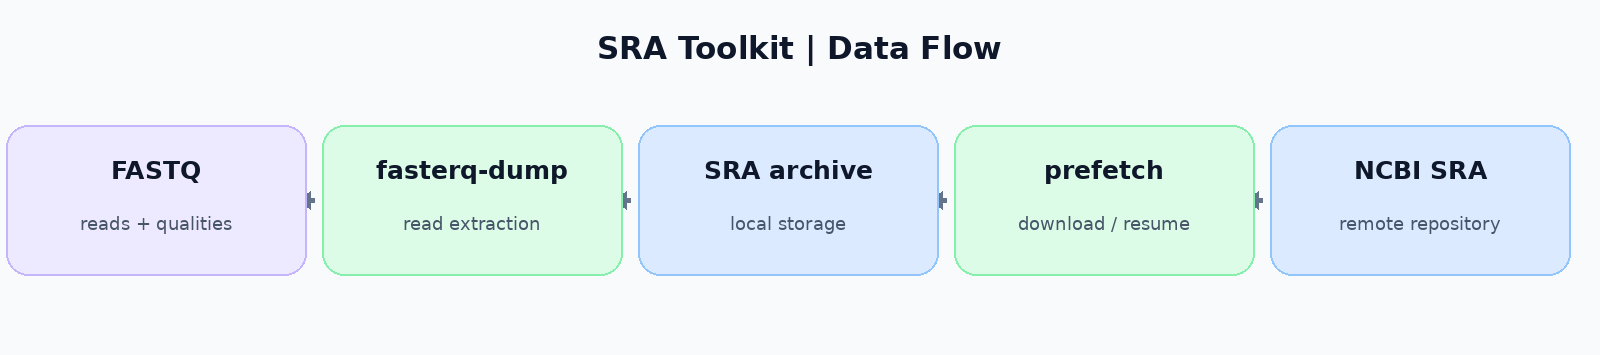

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">۱. نقشه راه و مفهوم ابزارها</h2>
<p>در SRA Toolkit، پایتون یک «هماهنگ‌کننده» است؛ ابزارهای NCBI برنامه‌های مستقلی هستند که از طریق <code dir="ltr">subprocess</code> اجرا می‌شوند.</p>
<ol><li><strong>پیدا کردن Run:</strong> شناسه‌هایی مثل <code dir="ltr">SRR000001</code> را در NCBI بررسی می‌کنیم.</li>
<li><strong>دانلود:</strong> <code dir="ltr">prefetch</code> محتوا و وابستگی‌های Run را به سیستم منتقل می‌کند.</li>
<li><strong>اعتبارسنجی:</strong> <code dir="ltr">vdb-validate</code> داده آرشیوشده را آزمایش می‌کند.</li>
<li><strong>تبدیل:</strong> <code dir="ltr">fasterq-dump</code> رکوردهای FASTQ و در حالت خاص FASTA را تولید می‌کند.</li>
<li><strong>کنترل:</strong> فایل، تعداد رکورد و مسیرها را بررسی می‌کنیم؛ سپس می‌توانیم به FastQC یا Salmon برویم.</li></ol>
<p><strong>شناسه‌های پرکاربرد:</strong> <code dir="ltr">GSE</code> مجموعه GEO؛ <code dir="ltr">SRP</code> مطالعه SRA؛ <code dir="ltr">SRX</code> آزمایش؛ <code dir="ltr">SRR</code> اجرای Run. برای دانلود، معمولاً شناسه Run لازم است.</p>
</div>

In [ ]:
# Cell 01 - Imports and Python environment | v1.2
from pathlib import Path
import concurrent.futures
import gzip
import io
import json
import os
import re
import shutil
import subprocess
import sys
import tempfile
from datetime import datetime, timezone

import pandas as pd
import requests
from IPython.display import display

print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('Current working directory:', Path.cwd())


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">2. ساخت پروژه و تنظیمات ایمن</h2>
<p>این پروژه روی <code dir="ltr">~/sra-learning-project</code> ایجاد می‌شود. اگر فضای خانه کم است، متغیر <code dir="ltr">PROJECT_DIR</code> را به یک درایو با فضای بیشتر تغییر دهید.</p>
<p>در ابتدا تنها درخواست فراداده به NCBI/ENA مجاز است. تنظیم‌های دانلود، تبدیل، FASTA و فشرده‌سازی خاموش‌اند تا هزینه شبکه و دیسک تحت کنترل باشد.</p></div>

In [ ]:
# Cell 02 - Project paths and safety flags | v1.2
PROJECT_DIR = Path.home() / 'sra-learning-project'
SRA_DIR = PROJECT_DIR / 'sra'
FASTQ_DIR = PROJECT_DIR / 'fastq'
FASTA_DIR = PROJECT_DIR / 'fasta'
TEMP_DIR = PROJECT_DIR / 'tmp'
LOG_DIR = PROJECT_DIR / 'logs'

for folder in [SRA_DIR, FASTQ_DIR, FASTA_DIR, TEMP_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

ACCESSION = 'SRR000001'  # Replace after checking metadata and download size
assert re.fullmatch(r'(SRR|ERR|DRR)\d+', ACCESSION), 'Run accession required'

DOWNLOAD_LIMIT = '1G'     # prefetch fails rather than downloading a larger Run
THREADS = min(4, os.cpu_count() or 1)
DO_DOWNLOAD = False
DO_VALIDATE = False
DO_CONVERT = False
DO_COMPRESS = False
DO_FASTA = False
DO_PARALLEL_DOWNLOADS = False
DO_FULL_COUNT = False

RUN_DIR = SRA_DIR / ACCESSION
RUN_FASTQ_DIR = FASTQ_DIR / ACCESSION
RUN_FASTA_DIR = FASTA_DIR / ACCESSION
RUN_TEMP_DIR = TEMP_DIR / ACCESSION

print('Accession:', ACCESSION)
print('Project:', PROJECT_DIR)
print('Thread count:', THREADS)
print('Download/conversion disabled by default.')


In [ ]:
# Cell 03 - Subprocess wrapper with streaming logs | v1.2
def run_logged(command, log_name, cwd=None):
    """Run an external command without a shell; print and save its combined output."""
    command = [str(value) for value in command]
    log_path = LOG_DIR / log_name
    print('COMMAND:', ' '.join(command))
    print('LOG:', log_path)
    with log_path.open('w', encoding='utf-8') as log:
        with subprocess.Popen(
            command, cwd=str(cwd) if cwd else None,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, errors='replace', bufsize=1
        ) as proc:
            for line in proc.stdout:
                print(line, end='')
                log.write(line)
                log.flush()
            code = proc.wait()
    if code != 0:
        raise RuntimeError(f'Exit code {code}. Inspect log: {log_path}')
    return log_path


def disk_gib(path):
    u = shutil.disk_usage(path)
    return {'total_GiB': round(u.total / 1024**3, 2),
            'free_GiB': round(u.free / 1024**3, 2)}

for folder in (SRA_DIR, FASTQ_DIR, TEMP_DIR):
    print(folder, disk_gib(folder))


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">3. پیدا کردن Run با API رسمی NCBI</h2>
<p>جست‌وجوی Run را از طریق <code dir="ltr">E-utilities</code> انجام می‌دهیم. این درخواست تنها فراداده دریافت می‌کند و Readهای حجیم را دانلود نمی‌کند.</p>
<p>اگر شبکه در دسترس نبود، می‌توانید این مرحله را بعداً اجرا کنید. به‌جای حدس‌زدن درباره تعداد Read یا Paired-end بودن، فراداده واقعی را می‌خوانیم.</p></div>

In [ ]:
# Cell 04 - Search accession with NCBI ESearch | v1.2
def ncbi_esearch_run(accession, timeout=30):
    url = 'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi'
    params = {'db': 'sra', 'term': f'{accession}[ACCN]', 'retmode': 'json'}
    response = requests.get(url, params=params, timeout=timeout)
    response.raise_for_status()
    return response.json()['esearchresult']

try:
    ncbi_search = ncbi_esearch_run(ACCESSION)
    print('Matched NCBI SRA records:', ncbi_search['count'])
    print('NCBI UIDs:', ncbi_search['idlist'])
except (requests.RequestException, ValueError, KeyError) as exc:
    ncbi_search = None
    print('Metadata request failed; check network/accession:', exc)


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">4. بررسی Layout و اندازه فایل‌ها با ENA Portal API</h2>
<p>برای مشاهده جدول Run از API آرشیو اروپایی ENA استفاده می‌کنیم. این API وابسته به <code dir="ltr">prefetch</code> نیست و در صورت وجود داده، فیلدهای <code dir="ltr">library_layout</code>، تعداد Readها و اندازه <strong>FASTQ فشرده‌شده ENA</strong> را گزارش می‌کند.</p>
<p><strong>نکته علمی:</strong> اندازه <code dir="ltr">fastq_bytes</code> معادل اندازه فایل SRA دانلودشده توسط NCBI نیست. نباید از آن به‌عنوان اندازه دقیق SRA استفاده کنیم.</p></div>

In [ ]:
# Cell 05 - Fetch ENA metadata | v1.2
def ena_run_report(accession, timeout=45):
    response = requests.get(
        'https://www.ebi.ac.uk/ena/portal/api/filereport',
        params={'accession': accession, 'result': 'read_run', 'format': 'tsv',
                'fields': 'run_accession,library_layout,library_strategy,read_count,base_count,fastq_bytes'},
        timeout=timeout,
    )
    response.raise_for_status()
    data = response.text.strip()
    if not data:
        raise ValueError('Empty ENA response')
    frame = pd.read_csv(io.StringIO(data), sep='\t', dtype=str)
    if frame.empty or 'run_accession' not in frame:
        raise ValueError('No usable metadata returned')
    return frame

try:
    metadata = ena_run_report(ACCESSION)
    display(metadata)
    metadata.to_csv(LOG_DIR / f'{ACCESSION}_ENA_runinfo.tsv', sep='\t', index=False)
except (requests.RequestException, ValueError, pd.errors.ParserError) as exc:
    metadata = pd.DataFrame()
    print('ENA metadata unavailable:', exc)


In [ ]:
# Cell 06 - Interpret ENA metadata and size | v1.2
if metadata.empty:
    print('No metadata to interpret. Revisit Cells 04 and 05 when online.')
else:
    row = metadata.iloc[0]
    print('Run:', row.get('run_accession'))
    print('Library layout:', row.get('library_layout'))
    print('Library strategy:', row.get('library_strategy'))
    print('Reported read count:', row.get('read_count'))
    raw = str(row.get('fastq_bytes', ''))
    lengths = [int(x) for x in raw.split(';') if x.isdigit()]
    if lengths:
        print('ENA gzipped FASTQ total (GiB):', round(sum(lengths) / 1024**3, 3))
        print('This is NOT the size of the NCBI SRA archive.')


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">5. دانلود Run با <code dir="ltr">prefetch</code></h2>
<p><code dir="ltr">prefetch</code> دریافت داده را انجام می‌دهد و اجرای مجدد همان دستور می‌تواند دانلود ناقص را ادامه دهد. نام پوشه Run را مطابق Accession حفظ می‌کنیم.</p>
<p>برای فعال‌کردن دانلود در بخش تنظیمات (سلول ۲)، <code dir="ltr">DO_DOWNLOAD = True</code> را بگذارید. در صورت بزرگ‌تر بودن داده از سقف <code dir="ltr">DOWNLOAD_LIMIT</code>، دانلود متوقف می‌شود. سقف را فقط پس از بررسی ظرفیت تغییر دهید.</p></div>

In [ ]:
# Cell 07 - Safe prefetch execution | v1.2
download_cmd = [
    'prefetch', ACCESSION,
    '-O', str(RUN_DIR),
    '--max-size', DOWNLOAD_LIMIT,
]
print('Planned command:', ' '.join(download_cmd))

if DO_DOWNLOAD:
    if not shutil.which('prefetch'):
        raise EnvironmentError('prefetch not found; select the correct Conda kernel.')
    run_logged(download_cmd, f'{ACCESSION}_prefetch.log')
else:
    print('SKIPPED: set DO_DOWNLOAD=True in Cell 02 after checking disk and size.')


In [ ]:
# Cell 08 - Inspect downloaded archive and disk needs | v1.2
sra_files = sorted(RUN_DIR.rglob('*.sra')) if RUN_DIR.exists() else []
if not sra_files:
    print('No local .sra archive yet; this is expected before prefetch.')
else:
    archive_bytes = sum(p.stat().st_size for p in sra_files)
    print('SRA file(s):', [str(p) for p in sra_files])
    print('SRA size (GiB):', round(archive_bytes / 1024**3, 3))
    print('Conservative TOTAL disk planning ~17x SRA (GiB):',
          round(17 * archive_bytes / 1024**3, 3))
    print('Output partition:', disk_gib(FASTQ_DIR))
    print('Scratch partition:', disk_gib(TEMP_DIR))
    print('Note: 17x is a heuristic, not an exact size guarantee.')


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">6. اعتبارسنجی آرشیو با <code dir="ltr">vdb-validate</code></h2>
<p>آرشیو دانلودشده را پیش از تبدیل اعتبارسنجی می‌کنیم. عبور از این آزمون نشان می‌دهد فایل از آزمون‌های ساختاری Toolkit عبور کرده است؛ <strong>کیفیت زیستی Readها</strong> را تأیید نمی‌کند.</p>
<p>برای اجرا، پس از دانلود <code dir="ltr">DO_VALIDATE = True</code> کنید.</p></div>

In [ ]:
# Cell 09 - Validate downloaded archive | v1.2
if DO_VALIDATE:
    if not sra_files:
        raise FileNotFoundError('Download SRA first; no .sra file found.')
    run_logged(['vdb-validate', str(RUN_DIR)], f'{ACCESSION}_validate.log')
else:
    print('SKIPPED: vdb-validate is disabled; set DO_VALIDATE=True when ready.')


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">7. بررسی فضای تبدیل و ساخت FASTQ</h2>
<p>تبدیل با <code dir="ltr">fasterq-dump</code> به فضای قابل‌توجهی برای خروجی و فایل‌های موقت نیاز دارد. طبق راهنمای رسمی، برآورد برنامه‌ریزی می‌تواند در مجموع نزدیک <strong>۱۷ برابر اندازه SRA</strong> باشد، ولی عدد واقعی با Run متفاوت است.</p>
<p>حالت <code dir="ltr">--split-files</code> Readهای مختلف یک Spot را جدا می‌کند. برای Runهای Paired-end متداول می‌تواند فایل‌های <code dir="ltr">*_1.fastq</code> و <code dir="ltr">*_2.fastq</code> تولید کند. همیشه نوع واقعی فایل‌ها را بعد از استخراج بررسی کنید.</p></div>

In [ ]:
# Cell 10 - Read-only preflight size check | v1.2
RUN_FASTQ_DIR.mkdir(parents=True, exist_ok=True)
RUN_TEMP_DIR.mkdir(parents=True, exist_ok=True)

size_cmd = ['fasterq-dump', str(RUN_DIR), '--split-files',
            '-O', str(RUN_FASTQ_DIR), '-t', str(RUN_TEMP_DIR),
            '--size-check', 'only']
if sra_files and shutil.which('fasterq-dump'):
    print('Checking conversion disk-space requirements...')
    try:
        run_logged(size_cmd, f'{ACCESSION}_sizecheck.log')
    except RuntimeError as exc:
        print('Space preflight failed:', exc)
else:
    print('SKIPPED: prefetch the Run and install Toolkit first.')


In [ ]:
# Cell 11 - Convert SRA to FASTQ with 4 threads | v1.2
fastq_cmd = ['fasterq-dump', str(RUN_DIR),
             '--split-files', '-O', str(RUN_FASTQ_DIR),
             '-t', str(RUN_TEMP_DIR), '-e', str(THREADS), '-p']
print('Planned command:', ' '.join(fastq_cmd))

existing_fastqs = list(RUN_FASTQ_DIR.glob('*.fastq'))
if DO_CONVERT:
    if not sra_files:
        raise FileNotFoundError('Download and validate the SRA archive first.')
    if existing_fastqs:
        raise FileExistsError('FASTQ already present. Inspect files first; do not overwrite blindly.')
    run_logged(fastq_cmd, f'{ACCESSION}_fasterq.log')
else:
    print('SKIPPED: set DO_CONVERT=True in Cell 02 after verifying free space.')


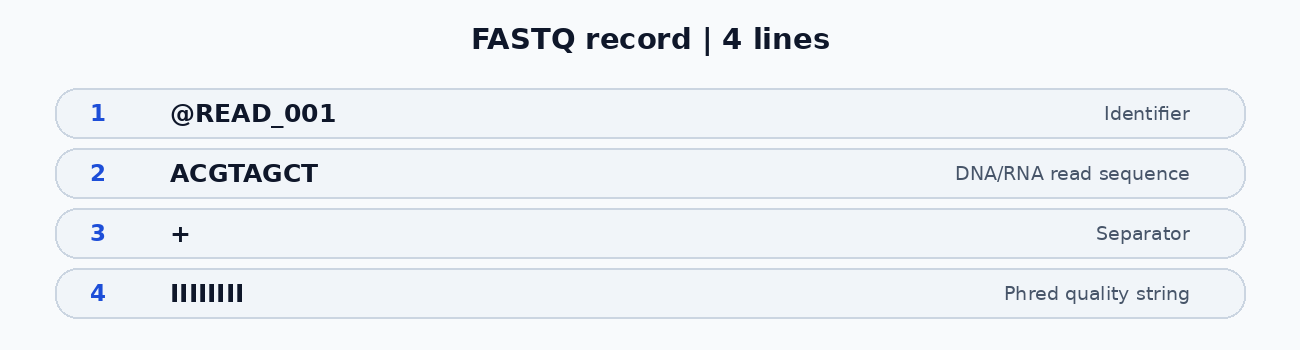

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">8. تفاوت FASTQ و FASTA</h2>
<p>FASTQ دارای چهار خط در هر رکورد است: شناسه، توالی، جداکننده و رشته کیفیت. طول رشته کیفیت باید با تعداد بازهای توالی برابر باشد. در FASTA تنها شناسه و توالی ثبت می‌شوند و نمره کیفیت بازها از دست می‌رود.</p>
<p>برای RNA-Seq معمولاً FASTQ را نگه دارید. <code dir="ltr">fasterq-dump --fasta-unsorted</code> فقط در صورت نیاز مشخص به FASTA استفاده شود؛ این حالت ترتیب اصلی Spotها را حفظ نمی‌کند.</p></div>

In [ ]:
# Cell 12 - Inspect output files and first FASTQ record | v1.2
raw_fastqs = sorted(RUN_FASTQ_DIR.glob('*.fastq'))
if not raw_fastqs:
    print('No FASTQ files available yet.')
else:
    for file in raw_fastqs:
        print(file.name, 'size (MiB):', round(file.stat().st_size/1024**2, 2))
    sample_file = raw_fastqs[0]
    with sample_file.open('rt', encoding='ascii') as handle:
        first_record = [handle.readline().rstrip('\n\r') for _ in range(4)]
    print('\nFirst record from:', sample_file.name)
    print('\n'.join(first_record))
    assert first_record[0].startswith('@')
    assert first_record[2].startswith('+')
    assert len(first_record[1]) == len(first_record[3])
    print('First-record structural checks passed. This is not a full FASTQ validation.')


In [ ]:
# Cell 13 - Read-count helper and self-test (no SRA needed) | v1.2
def fastq_record_count(path):
    """Count 4-line FASTQ records and check basic structure; reads the entire file."""
    path = Path(path)
    opener = gzip.open if path.suffix == '.gz' else open
    count = 0
    with opener(path, 'rt', encoding='ascii') as handle:
        while True:
            lines = [handle.readline() for _ in range(4)]
            if lines == ['', '', '', '']:
                return count
            if any(line == '' for line in lines):
                raise ValueError(f'Truncated FASTQ record in {path.name}')
            head, seq, plus, quality = [x.rstrip('\r\n') for x in lines]
            if not head.startswith('@') or not plus.startswith('+') or len(seq) != len(quality):
                raise ValueError(f'Invalid FASTQ record #{count+1} in {path.name}')
            count += 1

# A synthetic test is safe and works offline.
example_data = '@r1\nACGT\n+\nIIII\n@r2\nTGCA\n+\n####\n'
with tempfile.TemporaryDirectory() as td:
    demo = Path(td) / 'test.fastq'
    demo.write_text(example_data, encoding='ascii')
    assert fastq_record_count(demo) == 2
    zipped = Path(td) / 'test.fastq.gz'
    with gzip.open(zipped, 'wt', encoding='ascii') as handle:
        handle.write(example_data)
    assert fastq_record_count(zipped) == 2
print('Offline FASTQ parser self-test: OK')


In [ ]:
# Cell 14 - Optional full record count for real output | v1.2
all_fastq = sorted(RUN_FASTQ_DIR.glob('*.fastq')) + sorted(RUN_FASTQ_DIR.glob('*.fastq.gz'))
if DO_FULL_COUNT and all_fastq:
    for path in all_fastq:
        print(path.name, fastq_record_count(path), 'records')
else:
    print('SKIPPED: full counting reads every byte and may take time. Set DO_FULL_COUNT=True.')
    print('FASTQ files available:', [p.name for p in all_fastq])


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">9. فشرده‌سازی gzip و حفظ فایل خام</h2>
<p><code dir="ltr">fasterq-dump</code> گزینه مستقیم <code dir="ltr">--gzip</code> ندارد. می‌توان فایل‌های تولیدشده را پس از تبدیل با Python یا ابزار چندرشته‌ای <code dir="ltr">pigz</code> فشرده کرد.</p>
<p>در این Notebook فایل مبدأ را نگه می‌داریم و ابتدا فایل موقت <code dir="ltr">.part</code> می‌نویسیم؛ تنها پس از تکمیل فشرده‌سازی، نام نهایی فایل ثبت می‌شود. این روش از نام‌گذاری زودهنگام یک فایل ناقص جلوگیری می‌کند.</p></div>

In [ ]:
# Cell 15 - Optional gzip compression with atomic rename | v1.2
def gzip_keep_original(source, compresslevel=5):
    source = Path(source)
    destination = source.with_name(source.name + '.gz')
    partial = source.with_name(source.name + '.gz.part')
    if destination.exists():
        print('Already compressed:', destination.name)
        return destination
    if partial.exists():
        raise FileExistsError(f'Interrupted partial file exists: {partial}')
    try:
        with source.open('rb') as src, gzip.open(partial, 'wb', compresslevel=compresslevel) as dst:
            shutil.copyfileobj(src, dst, length=4*1024*1024)
        os.replace(partial, destination)
    except Exception:
        partial.unlink(missing_ok=True)
        raise
    return destination

if DO_COMPRESS:
    sources = sorted(RUN_FASTQ_DIR.glob('*.fastq'))
    if not sources:
        raise FileNotFoundError('No .fastq files to compress.')
    for src in sources:
        out = gzip_keep_original(src)
        print('Created:', out)
else:
    print('SKIPPED: enable DO_COMPRESS=True to generate .fastq.gz files.')


In [ ]:
# Cell 16 - Optional FASTA export (not recommended for normal RNA-seq) | v1.2
RUN_FASTA_DIR.mkdir(parents=True, exist_ok=True)
fasta_cmd = ['fasterq-dump', str(RUN_DIR), '--fasta-unsorted',
             '-O', str(RUN_FASTA_DIR)]
print('Planned FASTA command:', ' '.join(fasta_cmd))

if DO_FASTA:
    if not sra_files:
        raise FileNotFoundError('No local SRA archive found.')
    if list(RUN_FASTA_DIR.iterdir()):
        raise FileExistsError('FASTA directory is not empty; inspect before rerunning.')
    run_logged(fasta_cmd, f'{ACCESSION}_fasta.log')
else:
    print('SKIPPED: FASTA is optional and discards per-base quality scores.')


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">10. کنترل خطاهای متداول</h2>
<table style="border-collapse:collapse;width:100%;text-align:right" border="1" cellpadding="6">
<tr><th>نشانه</th><th>احتمال اصلی</th><th>راه بررسی</th></tr>
<tr><td><code dir="ltr">command not found</code></td><td>Kernel یا PATH نادرست</td><td>اجرای دستی <code dir="ltr">prefetch --version</code> در ترمینال</td></tr>
<tr><td><code dir="ltr">disk-limit exceeded</code></td><td>کمبود فضا در Scratch/Output</td><td>سلول ۱۰ و تغییر <code dir="ltr">-t</code></td></tr>
<tr><td><code dir="ltr">Killed</code></td><td>احتمال RAM/OOM یا محدودیت سیستم</td><td>بررسی <code dir="ltr">dmesg</code> و کاهش همزمانی</td></tr>
<tr><td>Timeout یا شکست دانلود</td><td>اتصال ناپایدار</td><td>اجرای دوباره <code dir="ltr">prefetch</code> با همان مقصد</td></tr>
<tr><td>فایل از پیش موجود</td><td>اجرای مجدد تبدیل</td><td>بررسی فایل‌ها؛ عدم حذف کورکورانه</td></tr>
</table>
<p><strong>دقت:</strong> کمبود RAM با کمبود فضای دیسک یکسان نیست. افزودن RAM مشکل پرشدن پارتیشن را حل نمی‌کند.</p>
</div>

In [ ]:
# Cell 17 - Resource report | v1.2
print('CPU logical threads:', os.cpu_count())
for label, directory in [('SRA', SRA_DIR), ('Output', FASTQ_DIR), ('Scratch', TEMP_DIR)]:
    print(label, disk_gib(directory))

meminfo = Path('/proc/meminfo')
if meminfo.exists():
    for line in meminfo.read_text().splitlines():
        if line.startswith(('MemTotal:', 'MemAvailable:')):
            print(line)


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">11. دریافت همزمان چند Run (بخش پیشرفته)</h2>
<p>با <code dir="ltr">ThreadPoolExecutor</code> می‌توان چند فراخوانی <code dir="ltr">prefetch</code> را موازی اجرا کرد. شروع با دو دانلود همزمان محافظه‌کارانه است. افزایش همزمانی همیشه باعث افزایش سرعت نمی‌شود و می‌تواند شبکه یا دیسک را اشباع کند.</p>
<p>توجه کنید که این روش با تعداد Threadهای خودِ <code dir="ltr">fasterq-dump -e</code> فرق دارد. از یک فهرست Runهای <strong>تأییدشده</strong> استفاده کنید؛ فهرست مثال را بدون بررسی تکمیل نکنید.</p></div>

In [ ]:
# Cell 18 - Parallel prefetch with per-Run logs | v1.2
ACCESSIONS_TO_DOWNLOAD = [ACCESSION]  # Add reviewed Run IDs here.


def prefetch_one(accession):
    if not re.fullmatch(r'(SRR|ERR|DRR)\d+', accession):
        return {'accession': accession, 'returncode': -1, 'reason': 'invalid accession'}
    cmd = ['prefetch', accession, '-O', str(SRA_DIR / accession),
           '--max-size', DOWNLOAD_LIMIT]
    log = LOG_DIR / f'{accession}_parallel_prefetch.log'
    with log.open('w', encoding='utf-8') as output:
        cp = subprocess.run(cmd, stdout=output, stderr=subprocess.STDOUT, check=False)
    return {'accession': accession, 'returncode': cp.returncode, 'log': str(log)}

if DO_PARALLEL_DOWNLOADS:
    if not shutil.which('prefetch'):
        raise EnvironmentError('prefetch is not available')
    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:
        outcomes = list(pool.map(prefetch_one, ACCESSIONS_TO_DOWNLOAD))
    display(pd.DataFrame(outcomes))
else:
    print('SKIPPED: set DO_PARALLEL_DOWNLOADS=True only after reviewing all Run IDs.')


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">12. ذخیره Manifest و بررسی نتایج</h2>
<p>در پایان نام فایل، اندازه و مسیر را در یک Manifest ثبت می‌کنیم. این فایل برای پیگیری نمونه‌ها و نوشتن پایپ‌لاین قابل‌تکرار مفید است. فقط وجود فایل، اثبات کامل بودن داده یا کیفیت بیولوژیکی آن نیست.</p></div>

In [ ]:
# Cell 19 - Generate output manifest (CSV and JSON) | v1.2
rows = []
for file in sorted(RUN_FASTQ_DIR.glob('*')):
    if file.is_file() and file.name.endswith(('.fastq', '.fastq.gz')):
        rows.append({'run_accession': ACCESSION,
                     'file_name': file.name,
                     'format': 'FASTQ.gz' if file.suffix == '.gz' else 'FASTQ',
                     'size_bytes': file.stat().st_size,
                     'absolute_path': str(file.resolve()),
                     'created_utc': datetime.now(timezone.utc).isoformat()})

manifest = pd.DataFrame(rows, columns=['run_accession','file_name','format',
                                       'size_bytes','absolute_path','created_utc'])
display(manifest)

manifest_path = LOG_DIR / f'{ACCESSION}_manifest.csv'
manifest.to_csv(manifest_path, index=False)
print('Manifest saved:', manifest_path)

summary = {'accession': ACCESSION, 'toolkit_versions_logged': bool(paths.get('prefetch')),
           'file_count': len(rows), 'total_output_bytes': sum(r['size_bytes'] for r in rows)}
(LOG_DIR / f'{ACCESSION}_summary.json').write_text(
    json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(summary, indent=2, ensure_ascii=False))


<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">13. جمع‌بندی، خودآزمایی و گام بعد</h2>
<p><strong>شرط پایان این جلسه:</strong> بتوانید توضیح دهید چرا <code dir="ltr">prefetch</code> را از <code dir="ltr">fasterq-dump</code> جدا کردیم، تفاوت FASTQ و FASTA چیست، و کدام بخش‌های سیستم در تبدیل فایل بزرگ محدودکننده‌اند.</p>
<p><strong>پرسش ۱:</strong> اگر دانلود در ۸۰٪ قطع شود، کدام دستور را دوباره اجرا می‌کنیم و چرا؟</p>
<p><strong>پرسش ۲:</strong> اگر FASTQ نهایی ۳۰ گیگابایت باشد، آیا ۳۰ گیگابایت فضای خالی برای تبدیل کافی است؟ چرا؟</p>
<p><strong>پرسش ۳:</strong> چرا داشتن دو فایل <code dir="ltr">*_1.fastq</code> و <code dir="ltr">*_2.fastq</code> به‌تنهایی اعتبار Read pairها را ثابت نمی‌کند؟</p>
<p><strong>تمرین تکمیلی:</strong> یک Run واقعی کوچک و عمومی انتخاب کنید، Layout آن را بررسی کنید، سپس دستورهای پیش‌فرض غیرفعال را <strong>یکی‌یکی</strong> فعال کنید. بعد از موفقیت، می‌توان همین ساختار را در Nextflow یا Snakemake ماژولار کرد.</p>
</div>

<div dir="rtl" style="text-align:right;line-height:1.95;font-family:Vazirmatn,'Noto Naskh Arabic',Tahoma,sans-serif"><h2 style="color:#145a72;margin-top:1.1em">منابع رسمی و محدودیت‌های علمی</h2>
<ul>
<li><a href="https://github.com/ncbi/sra-tools/wiki/08.-prefetch-and-fasterq-dump">NCBI: prefetch + fasterq-dump</a></li>
<li><a href="https://github.com/ncbi/sra-tools/wiki/HowTo:-fasterq-dump">NCBI: fasterq-dump options</a></li>
<li><a href="https://github.com/ncbi/sra-tools/wiki/05.-Toolkit-Configuration">NCBI: vdb-config</a></li>
<li><a href="https://bioconda.github.io/recipes/sra-tools/README.html">Bioconda: sra-tools</a></li>
<li><a href="https://www.ncbi.nlm.nih.gov/books/NBK25499/">NCBI: E-utilities</a></li>
<li><a href="https://github.com/enasequence/read_docs/blob/master/retrieval/programmatic-access/file-reports.rst">ENA: File Reports API</a></li>
</ul>
<p>در زمان ساخت دفترچه، دستورهای SRA Toolkit با مستندات رسمی بررسی شده‌اند. اجرای دانلود و تبدیل روی سیستم کاربر انجام نشده است. برخی Runها ممکن است دسترسی محدود، قالب فنی ویژه یا نیاز فضای بیشتری داشته باشند. برای RNA-Seq حرفه‌ای، کیفیت FASTQ و مشخصات آزمایش باید جداگانه بررسی شوند.</p>
</div>